# Document Clustering with Latent Variable Models

EM algorithm and MLE for unsupervised document clustering using mixture models.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/aryabhardwaj23/AI-PROJECTS/blob/main/Machine%20learning/Latent%20Variable%20Models%20and%20Neural%20Networks%2091/Document%20Clustering.ipynb)

# **Document Clustering**




**– mathematical formulations of the optimization functions of maximum likelihood estimation (MLE) for the document clustering model with complete data and incomplete data, respectively.**

**– the high-level idea of the EM algorithm to find MLE parameter estimates.**

I. Maximum Likelihood Estimation (MLE) for Document Clustering

Complete Data (Observed Cluster Assignments):

When each document $\mathbf{x}_i$ is assigned to a known cluster $z_i$, the likelihood function is:

$$
\mathcal{L}(\theta) = \prod_{i=1}^N P(\mathbf{x}_i, z_i \mid \theta) = \prod_{i=1}^N \pi_{z_i} \cdot P(\mathbf{x}_i \mid \theta_{z_i})
$$


where $\pi_{z_i}$ is the prior for cluster $z_i$, and $\theta_{z_i}$ are its parameters.

Incomplete Data (Unknown Cluster Assignments):

When cluster assignments are not observed, the likelihood is:

$$\mathcal{L}(\theta) = \prod_{i=1}^N \sum_{k=1}^K \pi_k \cdot P(\mathbf{x}_i \mid \theta_k)$$

The log-likelihood becomes:

$$\log \mathcal{L}(\theta) = \sum_{i=1}^N \log \left( \sum_{k=1}^K \pi_k \cdot P(\mathbf{x}_i \mid \theta_k) \right)$$

MLE with incomplete data hard to optimize because the log of a sum ($\log \sum$) does not simplify, making it impossible to solve for parameters in closed form. The optimization is non-convex and requires iterative algorithms.

---

II. High-Level Idea of the EM Algorithm

The Expectation-Maximization (EM) algorithm is used to find maximum likelihood estimates when data is incomplete or has latent variables.

E-step:Compute the posterior probability (responsibility) that each document belongs to each cluster, given current parameters:

  $$r_{ik} = \frac{\pi_k \cdot P(\mathbf{x}_i \mid \theta_k)}{\sum_{j=1}^K \pi_j \cdot P(\mathbf{x}_i \mid \theta_j)}$$

M-step: Update the parameters by maximizing the expected complete-data log-likelihood, using the responsibilities as soft assignments:
  

  $$\pi_k = \frac{1}{N} \sum_{i=1}^N r_{ik}$$


  $$\theta_k = \arg\max_\theta \sum_{i=1}^N r_{ik} \log P(\mathbf{x}_i \mid \theta_k)$$


EM alternates between estimating the hidden variables (E-step) and optimizing parameters (M-step), iteratively improving the likelihood until convergence.


**Expectation and Maximization steps of the (soft)-EM algorithm for Document Clus- tering, in a markdown cell. In particular, including all model parameters that should be learnt and the exact expression that should be used to update these parameters during the learning process (ie., E-step, M-step and assignments).**

Derivation of the (Soft)-EM Algorithm for Document Clustering

Suppose we have $N$ documents $\{\mathbf{x}_1, \dots, \mathbf{x}_N\}$ and $K$ clusters.  
Let $\pi_k$ be the mixing proportion (prior) for cluster $k$ ($\sum_{k=1}^K \pi_k = 1$), and $\theta_k$ be the parameters for cluster $k$ (e.g., multinomial word probabilities or Gaussian parameters).

E-step (Expectation Step)

For each document $i$ and cluster $k$, compute the responsibility (soft assignment) that cluster $k$ takes for document $i$:
$$
r_{ik} = \frac{\pi_k \, p(\mathbf{x}_i \mid \theta_k)}{\sum_{j=1}^K \pi_j \, p(\mathbf{x}_i \mid \theta_j)}
$$

- $r_{ik}$: posterior probability that document $i$ belongs to cluster $k$.
- $p(\mathbf{x}_i \mid \theta_k)$: likelihood of document $i$ under cluster $k$.

M-step (Maximization Step)

Update the parameters using the responsibilities:

- Cluster priors:
  $$
  \pi_k = \frac{N_k}{N} \qquad \text{where} \qquad N_k = \sum_{i=1}^N r_{ik}
  $$
- Cluster parameters:  
  For Gaussian mixtures:
  - Means:
  $$
\boldsymbol{\mu}_k = \frac{1}{N_k} \sum_{i=1}^N r_{ik} \, \mathbf{x}_i
$$
  - Covariances:
    $$
    \Sigma_k = \frac{1}{N_k} \sum_{i=1}^N r_{ik} (\mathbf{x}_i - \boldsymbol{\mu}_k)(\mathbf{x}_i - \boldsymbol{\mu}_k)^\top
    $$
  For multinomial mixtures (document clustering with word counts):
  - Word probabilities:
    $$
    \phi_{kv} = \frac{\sum_{i=1}^N r_{ik} x_{iv}}{\sum_{i=1}^N r_{ik} \sum_{v'=1}^V x_{iv'}}
    $$
    where $x_{iv}$ is the count of word $v$ in document $i$.

Assignments

- Soft assignment: Each document $i$ is assigned to clusters with probabilities $r_{ik}$.
- Hard assignment: Assign each document to the cluster with the highest responsibility:
  $$
  z_i = \arg\max_k \, r_{ik}
  $$



1. Initialize $\pi_k$ and $\theta_k$ for all $k$.
2. E-step: Compute $r_{ik}$ for all $i, k$.
3. M-step: Update $\pi_k$ and $\theta_k$ using $r_{ik}$.
4. Repeat E and M steps until convergence.



In [ ]:
#loading necessaring libraries and functions
import numpy as np
from sklearn.feature_extraction.text import CountVectorizer
import pandas as pd
import numpy as np
from scipy.stats import multivariate_normal
from scipy.special import logsumexp # using log-sum-exp trick to avoid numerical unstability as suggested in assignment instructions.
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

**Load Task2A.txt file .**

In [ ]:
labels = []
articles = []
with open('Task2A.txt', 'r') as file:
    for line in file:
        parts = line.strip().split('\t')
        if len(parts) == 2:
            label, article = parts
            labels.append(label.strip())
            articles.append(article.strip())

docs = pd.DataFrame(data = zip(labels, articles), columns=['label', 'article'])
docs.label = docs.label.astype('category')
docs.head()

,label,article
0,sci.crypt,ripem frequently asked questions archive name ...
1,sci.crypt,ripem frequently asked questions archive name ...
2,sci.crypt,ripem frequently noted vulnerabilities archive...
3,sci.crypt,certifying authority question answered if you ...
4,sci.crypt,rubber hose cryptanalysis some sick part of me...


In [ ]:
cv = CountVectorizer(lowercase=True, stop_words='english', min_df=5)
features = cv.fit_transform(articles).toarray()
print(features.shape)


(2373, 8094)


**EM algorithm**

**a):the EM algorithm is not limited to solving GMMs; make sure to assess and choose the appropriate model that fits your specific needs. b): When implementing the M-step, we will need to normalize the posterior probability matrix in a row-wise manner. Formally, if we need to normalize an N dimensional vector of log probabilities xi = log pi using Softmax, we might naively compute the following equation**
**$$
p_i = \frac{\exp(x_i)}{\sum_{n=1}^N \exp(x_n)}
$$**

 **Since each xi is a log probability which may be very large, and either negative or positive, then exponentiating might result in under- or overflow respectively. For example, exp(10000) = inf. We can simply use the log-sum-exp trick to avoid this numerical unstability. We consider the log-sum-exp operation:**

**$$
\mathrm{LSE}(x_1, \ldots, x_N) = c + \log \left( \sum_{n=1}^N \exp(x_n - c) \right)
$$**
**where we usually set c = max{x1, ..., xN } to ensure that the largest positive exponentiated term is exp(0) = 1, so we will definitely not overflow, and even if we underflow, the answer
2
N n=1
2
V VI
we should use this log-sum-exp trick during implementation.
Set the number of clusters K=4, and run the hard clustering (using hard-EM) and soft clus- tering (using soft-EM) on the provided data.
Perform a PCA on the clusterings that we got based on the Mixture Models. Then, plot the obtained clusters with different colors where x and y axes are the first two principal components. Based on your plots, discuss how and why the hard and soft clustering are different in a markdown cell.
Perceptron vs Neural Networks
will be sensible. Then the final equation will be
!!**
**$$
p_i = \exp\left( x_i - c - \log \sum_{n=1}^N \exp(x_n - c) \right)
$$(4)**

In [ ]:
class SoftMultinomialEM:
    def __init__(self, n_clusters, max_steps=100, tol=1e-5, smoothing=1e-2, seed=None):
        self.n_clusters = n_clusters
        self.max_steps = max_steps
        self.tol = tol
        self.smoothing = smoothing
        if seed is not None:
            np.random.seed(seed)

    def fit(self, doc_matrix, verbose=False):
        n_samples, n_features = doc_matrix.shape
        # Initialize cluster priors (theta) and word distributions (beta)
        self.theta = np.full(self.n_clusters, 1.0 / self.n_clusters)
        self.beta = np.random.rand(self.n_clusters, n_features) + self.smoothing
        self.beta /= self.beta.sum(axis=1, keepdims=True)

        for step in range(self.max_steps):
            # E-step: compute log probabilities and responsibilities
            log_beta = np.log(self.beta) # Compute log-probabilities for documents under each cluster.
            log_theta = np.log(self.theta)
            log_resp = doc_matrix @ log_beta.T + log_theta
            log_norm = logsumexp(log_resp, axis=1, keepdims=True) #Normalize using log-sum-exp for numerical stability.
            resp = np.exp(log_resp - log_norm) #Compute responsibilities (soft assignments to clusters).

            # M-step: update priors and word distributions
            cluster_totals = resp.sum(axis=0)
            theta_new = cluster_totals / n_samples #Update theta using average responsibilities.
            beta_new = resp.T @ doc_matrix + self.smoothing
            beta_new /= beta_new.sum(axis=1, keepdims=True) #Update beta (cluster word distributions) based on weighted word counts.

            # Check for convergence
            if np.allclose(self.beta, beta_new, atol=self.tol, rtol=self.tol):
                if verbose:
                    print(f"Soft-EM converged at step {step}")
                break

            self.theta = theta_new
            self.beta = beta_new

        return self

    def predict_proba(self, doc_matrix):
        log_beta = np.log(self.beta)
        log_theta = np.log(self.theta)
        log_resp = doc_matrix @ log_beta.T + log_theta
        log_norm = logsumexp(log_resp, axis=1, keepdims=True)
        resp = np.exp(log_resp - log_norm)
        return resp

    def predict(self, doc_matrix):
        return np.argmax(self.predict_proba(doc_matrix), axis=1)


In [ ]:
class HardMultinomialEM:
    def __init__(self, n_clusters, max_steps=100, tol=1e-5, smoothing=1e-2, seed=None):
        self.n_clusters = n_clusters
        self.max_steps = max_steps
        self.tol = tol
        self.smoothing = smoothing
        if seed is not None:
            np.random.seed(seed)

    def fit(self, doc_matrix, verbose=False):
        n_samples, n_features = doc_matrix.shape
        self.theta = np.full(self.n_clusters, 1.0 / self.n_clusters)
        self.beta = np.random.rand(self.n_clusters, n_features) + self.smoothing
        self.beta /= self.beta.sum(axis=1, keepdims=True)

        for step in range(self.max_steps):
            # E-step: compute log probabilities and assign each doc to one cluster
            log_beta = np.log(self.beta)
            log_theta = np.log(self.theta)
            log_resp = doc_matrix @ log_beta.T + log_theta
            assignments = np.argmax(log_resp, axis=1)
            hard_resp = np.zeros_like(log_resp)
            hard_resp[np.arange(n_samples), assignments] = 1

            # M-step: update priors and word distributions
            cluster_totals = hard_resp.sum(axis=0)
            theta_new = cluster_totals / n_samples
            beta_new = hard_resp.T @ doc_matrix + self.smoothing
            beta_new /= beta_new.sum(axis=1, keepdims=True)

            # Check for convergence
            if np.allclose(self.beta, beta_new, atol=self.tol, rtol=self.tol):
                if verbose:
                    print(f"Hard-EM converged at step {step}")
                break

            self.theta = theta_new
            self.beta = beta_new

        return self

    def predict_proba(self, doc_matrix):
        log_beta = np.log(self.beta)
        log_theta = np.log(self.theta)
        log_resp = doc_matrix @ log_beta.T + log_theta
        assignments = np.argmax(log_resp, axis=1)
        hard_resp = np.zeros_like(log_resp)
        hard_resp[np.arange(doc_matrix.shape[0]), assignments] = 1
        return hard_resp

    def predict(self, doc_matrix):
        return np.argmax(self.predict_proba(doc_matrix), axis=1)


**Set the number of clusters K=4, and run the hard clustering (using hard-EM) and soft clus- tering (using soft-EM) on the provided data.**

In [ ]:
# Suppose doc_matrix is your document-term matrix (e.g., from CountVectorizer)
soft_em = SoftMultinomialEM(n_clusters=4, max_steps=50, tol=1e-4, smoothing=1e-2, seed=42)
soft_em.fit(features, verbose=True)
soft_labels = soft_em.predict(features)

hard_em = HardMultinomialEM(n_clusters=4, max_steps=50, tol=1e-4, smoothing=1e-2, seed=42)
hard_em.fit(features, verbose=True)
hard_labels = hard_em.predict(features)


Soft-EM converged at step 18
Hard-EM converged at step 16


**Perform a PCA on the clusterings that you get based on the Mixture Models. Then, plot the obtained clusters with different colors where x and y axes are the first two principal components.**


In [ ]:

pca = PCA(n_components=2, random_state=42)
features_2d = pca.fit_transform(features)


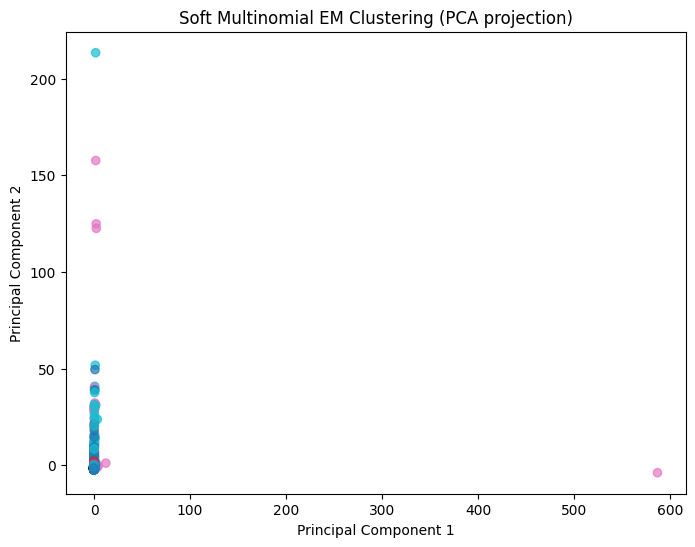

In [ ]:
soft_labels = soft_em.predict(features)

plt.figure(figsize=(8,6))
scatter = plt.scatter(features_2d[:, 0], features_2d[:, 1], c=soft_labels, cmap='tab10', alpha=0.7)
plt.title("Soft Multinomial EM Clustering (PCA projection)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.show()


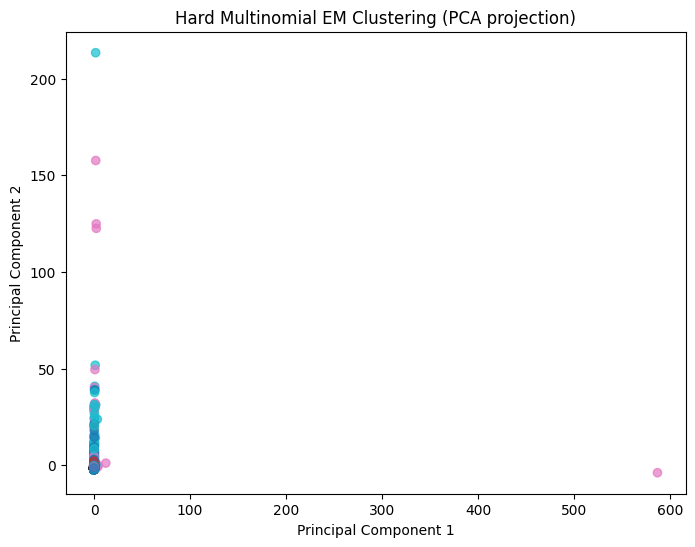

In [ ]:
hard_labels = hard_em.predict(features)

plt.figure(figsize=(8,6))
scatter = plt.scatter(features_2d[:, 0], features_2d[:, 1], c=hard_labels, cmap='tab10', alpha=0.7)
plt.title("Hard Multinomial EM Clustering (PCA projection)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()


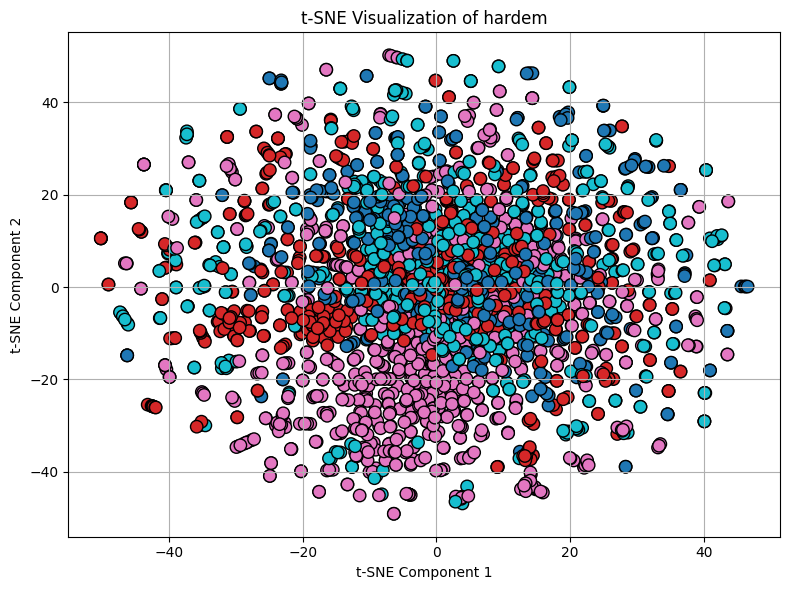

In [ ]:
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE

# Step 1: Predict cluster labels
labels = hard_em.predict(features)

# Step 2: Reduce dimensionality to 2D using t-SNE
tsne = TSNE(n_components=2, perplexity=30, random_state=42)
doc_2d = tsne.fit_transform(features)

# Step 3: Plot
plt.figure(figsize=(8, 6))
scatter = plt.scatter(doc_2d[:, 0], doc_2d[:, 1], c=labels, cmap='tab10', s=80, edgecolor='k')
plt.title("t-SNE Visualization of hardem")
plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.grid(True)
plt.tight_layout()
plt.show()


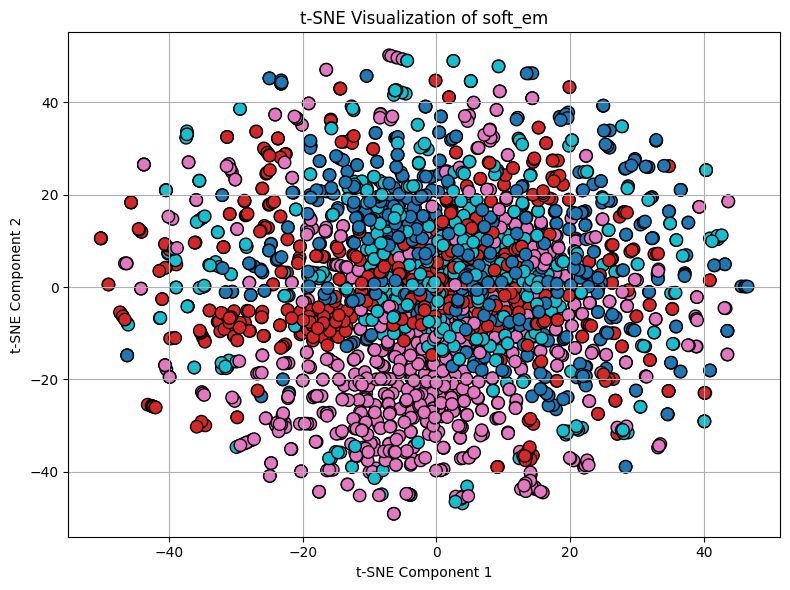

In [ ]:
labels = soft_em.predict(features)

# Step 2: Reduce dimensionality to 2D using t-SNE
tsne = TSNE(n_components=2, perplexity=30, random_state=42)
doc_2d = tsne.fit_transform(features)

# Step 3: Plot
plt.figure(figsize=(8, 6))
scatter = plt.scatter(doc_2d[:, 0], doc_2d[:, 1], c=labels, cmap='tab10', s=80, edgecolor='k')
plt.title("t-SNE Visualization of soft_em")
plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.grid(True)
plt.tight_layout()
plt.show()

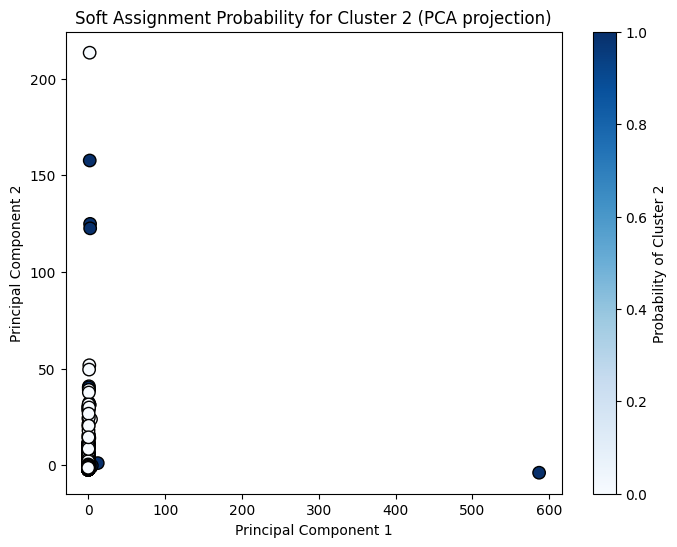

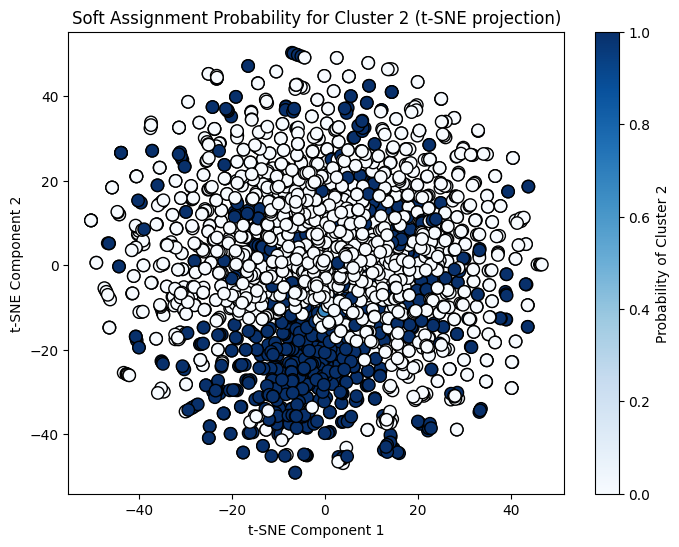

In [ ]:
# Get soft assignment probabilities (responsibilities)
soft_probs = soft_em.predict_proba(features)

# Choose the cluster you want to visualize
cluster_idx = 2

# For PCA
plt.figure(figsize=(8,6))
plt.scatter(
    features_2d[:, 0],
    features_2d[:, 1],
    c=soft_probs[:, cluster_idx],
    cmap='Blues',  #colormap
    s=80,
    edgecolor='k'
)
plt.title(f"Soft Assignment Probability for Cluster {cluster_idx} (PCA projection)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(label=f"Probability of Cluster {cluster_idx}")
plt.show()

# For t-SNE
plt.figure(figsize=(8,6))
plt.scatter(
    doc_2d[:, 0],
    doc_2d[:, 1],
    c=soft_probs[:, cluster_idx],
    cmap='Blues',
    s=80,
    edgecolor='k'
)
plt.title(f"Soft Assignment Probability for Cluster {cluster_idx} (t-SNE projection)")
plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.colorbar(label=f"Probability of Cluster {cluster_idx}")
plt.show()


After applying t-SNE normalization, the cluster structure in both hard and soft EM results becomes much clearer. Each cluster forms a distinct group in the t-SNE projection, with points of the same color (cluster) grouped together.

Both hard and soft EM produce similar cluster groupings in the t-SNE visualization, indicating that the underlying data structure is well captured by both approaches. The main difference is that hard EM assigns each point to a single cluster, while soft EM allows for probabilistic assignments, but for visualization, soft clustering is shown in both ways for better understanding.

t-SNE is especially effective here because it preserves local neighborhoods and reveals the true cluster structure of the high-dimensional data, which PCA could not show due to outliers and variance imbalance.
